# Thirty Years of Disco Biscuits Setlists

SIADS 521 dashboard assignment.

## 1. Introduction

The Disco Biscuits have played more than 1900 shows since 1995, and they rarely play a song the same way twice: songs run into each other, split around other songs, and drop out of rotation for years. This dashboard asks how the band's song rotation and segues changed from 1995 to 2026. It lets a reader pick an era, a state or a single song and see which songs led the rotation and which song-to-song transitions defined that period.

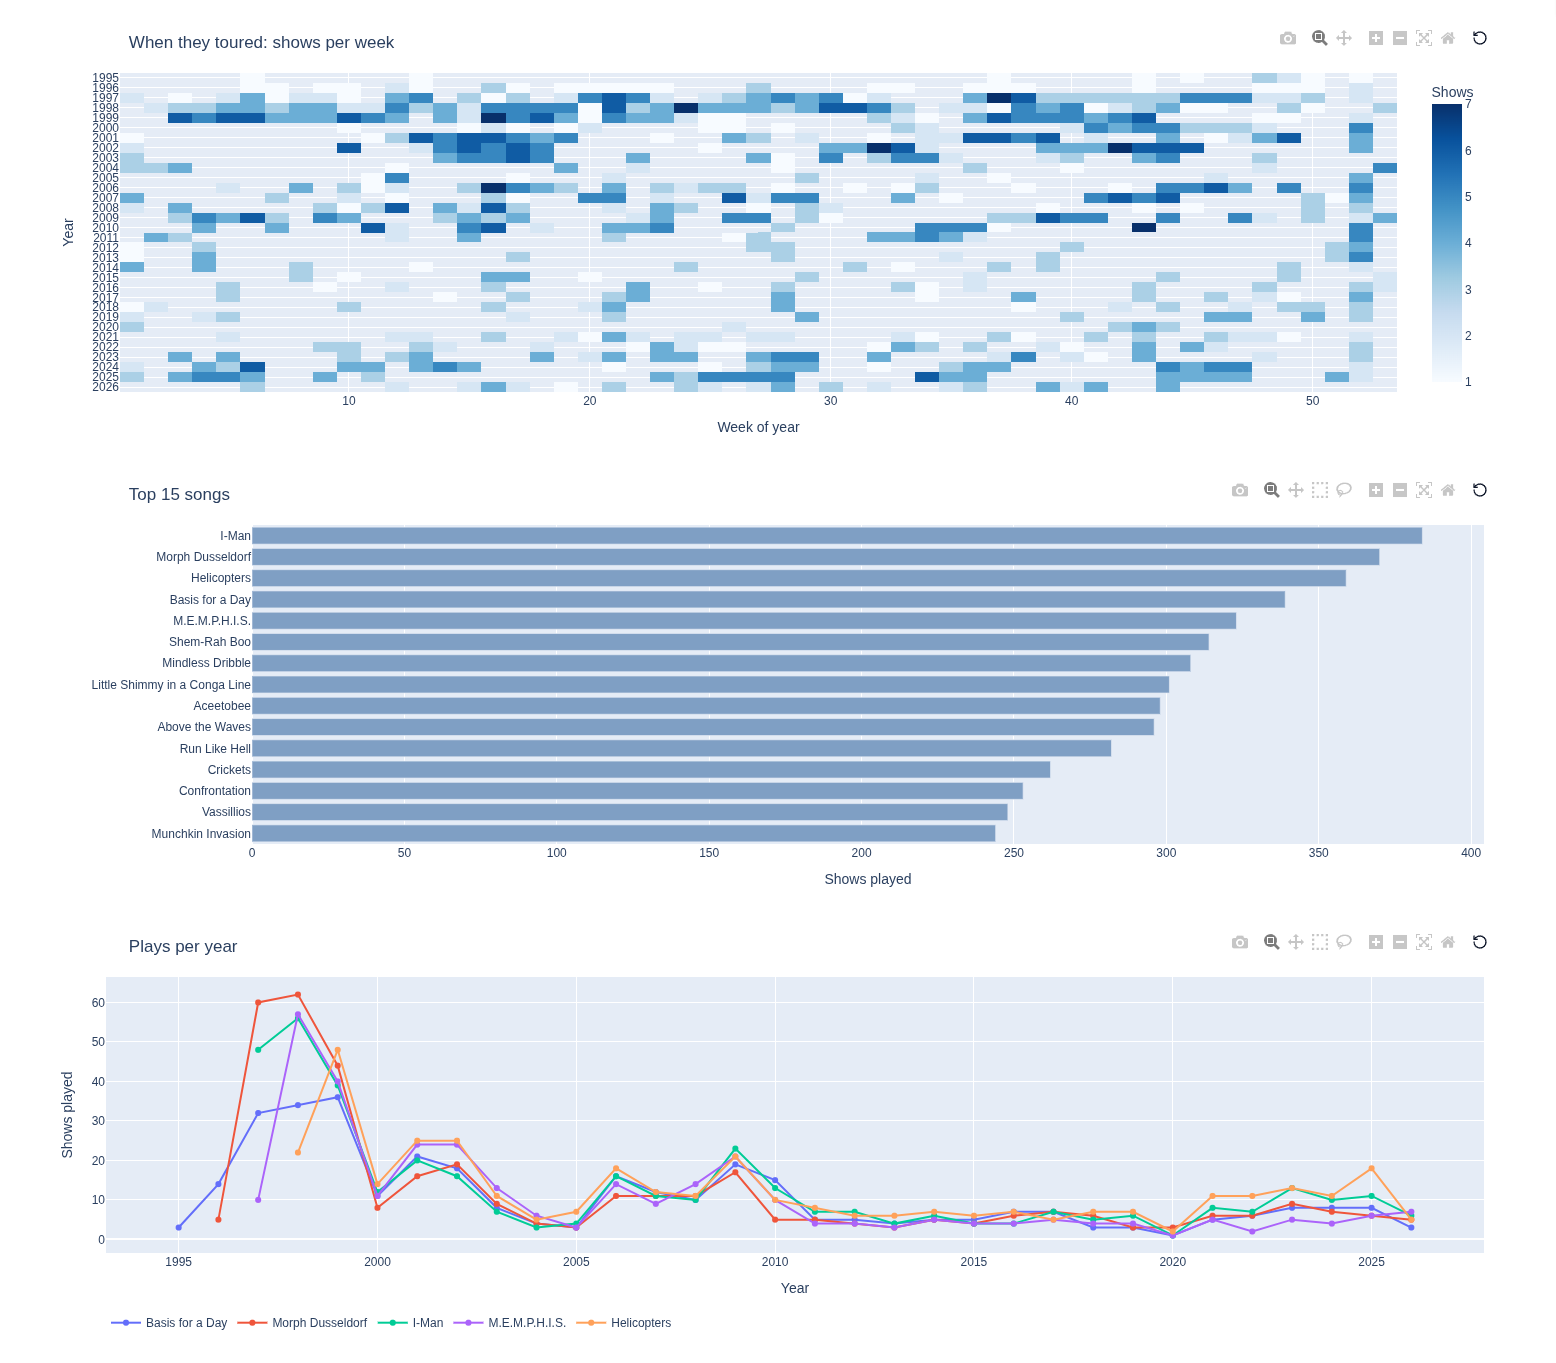


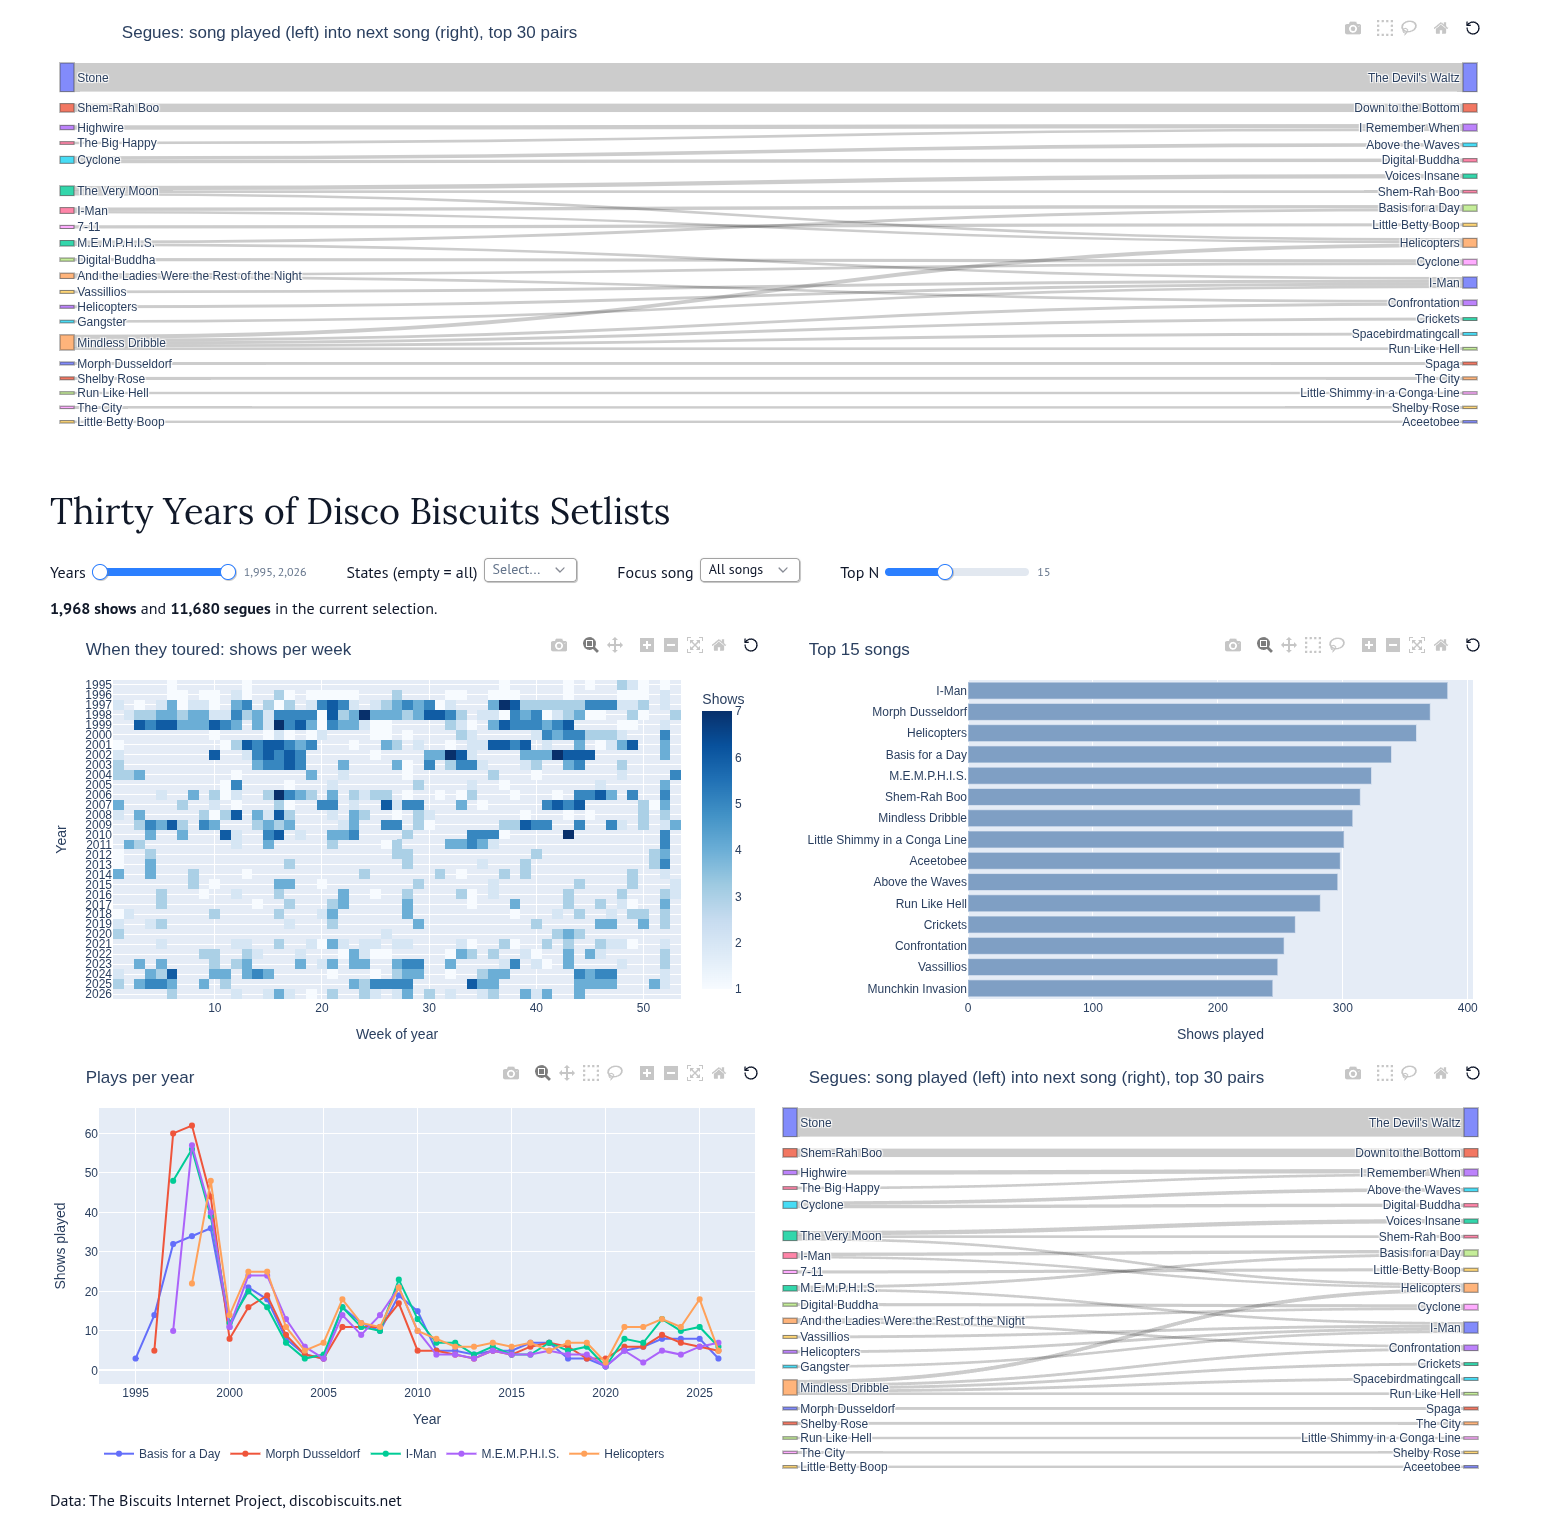

**Live dashboard:** https://avdrav1.github.io/siads521-biscuits/

## 2. Library choice and fit

**Library.** The dashboard uses marimo for layout and interactivity and Plotly for the charts.

**Background.** Akshay Agrawal and Myles Scolnick created marimo. It is open source under the Apache 2.0 license. Install it with `pip install marimo` and start it with `marimo edit dashboard.py`.

**Declarative or procedural.** marimo is reactive. Each cell declares the variables it reads and writes, and marimo builds a dependency graph from them. When a slider changes, marimo reruns every cell that depends on it. I declare what each chart depends on; I write no callbacks. Plotly Express is declarative in the same spirit: one call maps columns to a chart.

**Jupyter integration.** marimo replaces Jupyter and does not run inside it. A marimo notebook is a plain `.py` file. `marimo convert notebook.ipynb -o notebook.py` imports a Jupyter notebook, and `marimo export ipynb` writes one back. This report stays in Jupyter; the dashboard lives in `dashboard.py`.

**Limitations.** The WebAssembly export supports many but not all packages; the exported page needs internet access to load its Python runtime; marimo forbids defining the same variable in two cells.

**Why it fits this data.** The data is four small CSV files, so the whole dashboard can run in the browser with no server. One year slider must filter four charts drawn from three tables (shows, song plays, segue pairs). In marimo that is one filter cell that the four chart cells read. The segue table is a directed graph of song-to-song flows, and Plotly draws it as a Sankey from the source, target and count columns that table already holds.

**Alternative rejected.** I considered Plotly Dash. It handles the same charts, but it needs a running Python server, and each linked control needs a hand-written callback. A free host that sleeps would put the "publicly runnable" requirement at risk. marimo exports to static files that GitHub Pages serves for free.

## 3. Data

### Source

- **Source:** The Biscuits Internet Project (BIP), https://discobiscuits.net, a fan-run database of Disco Biscuits shows and setlists.
- **Access:** BIP's public MCP endpoint at `https://discobiscuits.net/mcp`, documented at https://discobiscuits.net/mcp-info. The code below calls two of its tools, `get_shows_by_year` and `get_setlists`, over plain HTTP.
- **License:** BIP publishes no open data license. Its terms (https://discobiscuits.net/terms) say the site runs for educational and informational purposes and bar commercial use.
- **Snapshot:** The pull caches raw JSON under `data/raw/` and writes cleaned CSVs to `data/`. Commit the CSVs so the dashboard and any reader can run without calling BIP.

In [20]:
import json
import time
from pathlib import Path

import pandas as pd
import requests

MCP_URL = "https://discobiscuits.net/mcp"
FIRST_YEAR, LAST_YEAR = 1995, 2026
BATCH_SIZE = 20      # setlists per request
PAUSE_SECONDS = 2  # be polite to a fan-run server

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

### Pull step 1: a minimal MCP client

MCP is JSON-RPC over HTTP. The client opens a session, then calls a tool by name. The server may answer with plain JSON or with a server-sent event stream, so `_parse` handles both. A tool's result arrives as a JSON string inside `result.content[0].text`.

In [21]:
class BipClient:
    def __init__(self, url=MCP_URL):
        self.url = url
        self.session = requests.Session()
        self.session.headers.update({
            "Content-Type": "application/json",
            "Accept": "application/json, text/event-stream",
        })
        self._next_id = 0
        self._initialized = False

    @staticmethod
    def _parse(response):
        """Return the JSON-RPC message from a JSON or event-stream reply."""
        if "text/event-stream" in response.headers.get("Content-Type", ""):
            message = None
            for line in response.text.splitlines():
                if line.startswith("data:"):
                    payload = json.loads(line[5:].strip())
                    if "result" in payload or "error" in payload:
                        message = payload
            if message is None:
                raise RuntimeError("No JSON-RPC result in event stream")
            return message
        return response.json()

    def _rpc(self, method, params=None, notify=False):
        body = {"jsonrpc": "2.0", "method": method}
        if params is not None:
            body["params"] = params
        if not notify:
            self._next_id += 1
            body["id"] = self._next_id
        for attempt in range(6):
            response = self.session.post(self.url, json=body, timeout=60)
            if response.status_code != 429:
                break
            try:
                wait = int(response.headers.get("Retry-After", ""))
            except ValueError:
                wait = 15 * 2 ** attempt   # 15s, 30s, 60s, ...
            print(f"Rate limited; waiting {wait}s")
            time.sleep(wait)
        response.raise_for_status()
        session_id = response.headers.get("Mcp-Session-Id")
        if session_id:
            self.session.headers["Mcp-Session-Id"] = session_id
        if notify:
            return None
        message = self._parse(response)
        if "error" in message:
            raise RuntimeError(message["error"])
        return message["result"]

    def _initialize(self):
        self._rpc("initialize", {
            "protocolVersion": "2025-03-26",
            "capabilities": {},
            "clientInfo": {"name": "siads521-notebook", "version": "0.1"},
        })
        self._rpc("notifications/initialized", notify=True)
        self._initialized = True

    def call_tool(self, name, arguments):
        if not self._initialized:
            self._initialize()
        result = self._rpc("tools/call", {"name": name, "arguments": arguments})
        text = result["content"][0]["text"]
        if result.get("isError"):
            raise RuntimeError(text)
        return json.loads(text)


def cached(path, fetch):
    """Read JSON from disk if present; otherwise fetch, save, and pause."""
    if path.exists():
        return json.loads(path.read_text())
    payload = fetch()
    path.write_text(json.dumps(payload))
    time.sleep(PAUSE_SECONDS)
    return payload


client = BipClient()

### Pull step 2: every show, year by year

`get_shows_by_year` returns one record per show with its slug, date, venue, city, state and fan rating. The slug is the key for the setlist pull.

In [22]:
show_records = []
for year in range(FIRST_YEAR, LAST_YEAR + 1):
    payload = cached(
        RAW_DIR / f"shows_{year}.json",
        lambda: client.call_tool("get_shows_by_year", {"year": year, "limit": 500}),
    )
    shows_in_year = payload.get("shows", [])
    if len(shows_in_year) >= 500:
        print(f"Warning: {year} hit the 500-show limit and may be truncated")
    show_records.extend(shows_in_year)

print(len(show_records), "shows pulled")

1968 shows pulled


### Pull step 3: every setlist, in batches

`get_setlists` takes a list of show slugs. Each setlist holds sets (`S1`, `S2`, `E1`), and each set holds tracks with a position, a song title and a segue marker.

The single-show tool `get_setlist` returns no slug, and I have not confirmed the batch reply's exact shape. `unpack_setlists` therefore accepts a list or a wrapped list, and pairs setlists to slugs by a slug field if one exists, or by order if the counts match. If neither works it stops, so a mismatch cannot pass silently.

In [23]:
def unpack_setlists(payload, slugs):
    """Return {slug: setlist} for one batch reply."""
    if isinstance(payload, dict):
        for key in ("setlists", "results", "shows", "data"):
            if isinstance(payload.get(key), list):
                payload = payload[key]
                break
        else:
            if all(slug in payload for slug in slugs):
                return {slug: payload[slug] for slug in slugs}
            raise ValueError(f"Unrecognized batch shape: keys {list(payload)[:8]}")
    out = {}
    for index, item in enumerate(payload):
        slug = item.get("slug") or item.get("showSlug")
        setlist = item.get("setlist", item)
        if slug is None:
            if len(payload) != len(slugs):
                raise ValueError("Batch has no slugs and its length differs from the request")
            slug = slugs[index]
        out[slug] = setlist
    return out


all_slugs = [show["slug"] for show in show_records]
setlists = {}
for start in range(0, len(all_slugs), BATCH_SIZE):
    batch = all_slugs[start:start + BATCH_SIZE]
    payload = cached(
        RAW_DIR / f"setlists_{start:05d}.json",
        lambda: client.call_tool("get_setlists", {"showSlugs": batch}),
    )
    setlists.update(unpack_setlists(payload, batch))

print(len(setlists), "setlists pulled for", len(all_slugs), "shows")

1967 setlists pulled for 1968 shows


### Cleaning step 1: build the shows table

Parse the date and derive year, month and weekday for filters and the calendar plot. Sort by date. Drop duplicate slugs in case a show appears twice.

In [24]:
shows = pd.DataFrame(show_records).drop_duplicates(subset="slug")
shows = shows.rename(columns={
    "venueName": "venue", "venueCity": "city", "venueState": "state",
    "averageRating": "rating", "ratingsCount": "ratings_count",
})
shows["date"] = pd.to_datetime(shows["date"])
shows["year"] = shows["date"].dt.year
shows["month"] = shows["date"].dt.month
shows["weekday"] = shows["date"].dt.day_name()
keep = ["slug", "date", "year", "month", "weekday", "venue", "city", "state",
        "rating", "ratings_count"]
shows = shows[[c for c in keep if c in shows.columns]].sort_values("date").reset_index(drop=True)
shows.head()

,slug,date,year,month,weekday,venue,city,state,rating,ratings_count
0,1995-02-11-unknown-venue-philadelphia-pa,1995-02-11,1995,2,Saturday,Unknown Venue,Philadelphia,PA,5.0,1
1,1995-04-01-unknown-venue-philadelphia-pa,1995-04-01,1995,4,Saturday,Unknown Venue,Philadelphia,PA,0.0,0
2,1995-09-16-zeta-psi-university-of-pennsylvania...,1995-09-16,1995,9,Saturday,"Zeta Psi, University of Pennsylvania",Philadelphia,PA,0.0,0
3,1995-10-23-unknown-location,1995-10-23,1995,10,Monday,Unknown Location,,,0.0,0
4,1995-11-09-unknown-location,1995-11-09,1995,11,Thursday,Unknown Location,,,0.0,0


### Cleaning step 2: flatten setlists to one row per track

Each row is one song performance. `show_order` numbers tracks across the whole show so the running order survives the flattening. Song titles are stripped of stray whitespace so one song cannot count as two.

In [25]:
track_rows = []
for slug, setlist in setlists.items():
    order = 0
    for set_ in (setlist or {}).get("sets", []):
        for track in sorted(set_.get("tracks", []), key=lambda t: t.get("position") or 0):
            order += 1
            track_rows.append({
                "slug": slug,
                "set_name": set_.get("label") or set_.get("name"),
                "position": track.get("position"),
                "show_order": order,
                "song": (track.get("songTitle") or track.get("song") or "").strip(),
                "song_slug": track.get("songSlug"),
                "segue_raw": track.get("segue"),
                "duration_sec": track.get("duration"),
                "all_timer": track.get("allTimer"),
                "flags": "|".join(track.get("flags") or []),
                "notes": track.get("note") or track.get("notes"),
            })

tracks = pd.DataFrame(track_rows)
assert len(tracks) > 0, "No tracks parsed: check field names against data/raw"
tracks = tracks[tracks["song"] != ""]
print(len(tracks), "track rows")

23327 track rows


### Cleaning step 3: normalize the segue marker

The raw field is inconsistent: `>` for a segue, and both `null` and an empty string for none. Print the raw values first, then reduce them to a boolean. Any marker other than `>` shows up in the printed counts; decide then whether it counts as a segue.

In [26]:
print(tracks["segue_raw"].fillna("<null>").replace("", "<empty>").value_counts())

tracks["segue"] = tracks["segue_raw"].fillna("").str.strip().eq(">")

segue_raw
>          11684
<null>      8901
<empty>     2742
Name: count, dtype: int64


### Cleaning step 4: label set types

Set names are codes such as `S1`, `S2` and `E1`. Map the first letter to a readable type for the set filter. Unknown codes fall to "Other" and are printed.

In [27]:
set_types = {"S": "Set", "E": "Encore"}
tracks["set_type"] = tracks["set_name"].fillna("").str[:1].map(set_types).fillna("Other")
print(tracks.loc[tracks["set_type"] == "Other", "set_name"].value_counts())

Series([], Name: count, dtype: int64)


### Cleaning step 5: attach show fields and drop shows without setlists

Join date, year, venue and state onto each track so every chart can filter on them. Shows with no recorded setlist stay in `shows` (they still belong on the calendar) but are flagged, so song charts can exclude them.

In [28]:
tracks = tracks.merge(shows[["slug", "date", "year", "venue", "city", "state"]],
                      on="slug", how="inner")
tracks = tracks.sort_values(["date", "slug", "show_order"]).reset_index(drop=True)

shows["has_setlist"] = shows["slug"].isin(tracks["slug"])
print((~shows["has_setlist"]).sum(), "shows have no setlist")

98 shows have no setlist


### Cleaning step 6: build the segue pairs table

A segue pair is two consecutive tracks in the same set where the first track carries the segue marker. This is the edge list for the Sankey or chord chart.

The band often splits a song around another (Basis > Ladies > Basis). That yields two pairs, Basis to Ladies and Ladies to Basis, which is correct for a flow chart: both transitions happened.

In [29]:
nxt = tracks.groupby(["slug", "set_name"])["song"].shift(-1)
segue_pairs = tracks.assign(target=nxt)
segue_pairs = segue_pairs[segue_pairs["segue"] & segue_pairs["target"].notna()]
segue_pairs = segue_pairs.rename(columns={"song": "source"})[
    ["slug", "date", "year", "venue", "state", "set_name", "set_type", "source", "target"]
].reset_index(drop=True)
print(len(segue_pairs), "segue pairs")
segue_pairs.head()

11680 segue pairs


,slug,date,year,venue,state,set_name,set_type,source,target
0,1995-04-01-unknown-venue-philadelphia-pa,1995-04-01,1995,Unknown Venue,PA,S1,Set,The Other One,Nughuffer
1,1995-04-01-unknown-venue-philadelphia-pa,1995-04-01,1995,Unknown Venue,PA,S1,Set,The Other One,Mary Had a Little Lamb
2,1995-04-01-unknown-venue-philadelphia-pa,1995-04-01,1995,Unknown Venue,PA,S1,Set,The Other One,Run Like an Antelope
3,1995-09-16-zeta-psi-university-of-pennsylvania...,1995-09-16,1995,"Zeta Psi, University of Pennsylvania",PA,S2,Set,Help on the Way,Slipknot!
4,1995-09-16-zeta-psi-university-of-pennsylvania...,1995-09-16,1995,"Zeta Psi, University of Pennsylvania",PA,S2,Set,In Memory of Elizabeth Reed,The Other One


### Cleaning step 7: count song plays per show, not per track

Because songs repeat within a show, counting track rows would inflate split songs. `song_shows` holds one row per song per show. Use it for the frequency bar chart and the plays-over-time line chart.

In [30]:
song_shows = (tracks.groupby(["slug", "date", "year", "venue", "state", "song"], as_index=False)
                    .agg(times_in_show=("show_order", "size")))

song_summary = (song_shows.groupby("song")
                .agg(shows_played=("slug", "nunique"),
                     first_played=("date", "min"),
                     last_played=("date", "max"))
                .sort_values("shows_played", ascending=False)
                .reset_index())
song_summary.head(10)

,song,shows_played,first_played,last_played
0,I-Man,384,1997-04-19,2026-10-02
1,Morph Dusseldorf,370,1996-09-12,2026-10-31
2,Helicopters,359,1998-08-28,2026-09-26
3,Basis for a Day,339,1995-11-09,2026-10-30
4,M.E.M.P.H.I.S.,323,1997-11-20,2026-10-03
5,Shem-Rah Boo,314,1997-01-17,2026-10-29
6,Mindless Dribble,308,1998-02-19,2026-10-11
7,Little Shimmy in a Conga Line,301,1998-02-26,2026-10-03
8,Aceetobee,298,1995-11-09,2026-10-11
9,Above the Waves,296,1998-12-29,2026-09-01


### Checks and snapshot

Check the tables against known facts before trusting them, then write the CSVs the dashboard reads. BIP's own statistics list Basis for a Day at 339 plays as of November 2026; a count far from that means the pull or the cleaning is wrong.

In [31]:
assert shows["slug"].is_unique
assert tracks["slug"].isin(shows["slug"]).all()
assert not (segue_pairs["source"] == "").any()

print("Shows:", len(shows), "from", shows["date"].min().date(), "to", shows["date"].max().date())
print("Tracks:", len(tracks), "| distinct songs:", tracks["song"].nunique())
print("Segue pairs:", len(segue_pairs))
print("Basis for a Day, shows played:",
      song_summary.loc[song_summary["song"] == "Basis for a Day", "shows_played"].squeeze())

shows.to_csv(DATA_DIR / "shows.csv", index=False)
tracks.drop(columns=["segue_raw"]).to_csv(DATA_DIR / "tracks.csv", index=False)
segue_pairs.to_csv(DATA_DIR / "segue_pairs.csv", index=False)
song_shows.to_csv(DATA_DIR / "song_shows.csv", index=False)

Shows: 1968 from 1995-02-11 to 2026-10-31
Tracks: 23327 | distinct songs: 553
Segue pairs: 11680
Basis for a Day, shows played: 339


### Columns used

| Table | Column | Description |
|---|---|---|
| shows | slug | Unique show id (date, venue, city, state) |
| shows | date, year, month, weekday | Show date and derived parts |
| shows | venue, city, state | Where the show took place |
| shows | rating, ratings_count | Mean fan rating and number of ratings |
| shows | has_setlist | False if BIP holds no setlist for the show |
| tracks | set_name, set_type | Set code (S1, E1) and readable type |
| tracks | position, show_order | Order within the set and within the show |
| tracks | song | Song title |
| tracks | segue | True if the song ran into the next without a stop |
| segue_pairs | source, target | The two songs joined by a segue |
| song_shows | times_in_show | Times the song appeared in that show |


In [32]:
from IPython.display import Markdown

tables = {"shows": shows, "tracks": tracks,
          "segue_pairs": segue_pairs, "song_shows": song_shows}

lines = ["| Table | Rows | Columns | File size |", "|---|---|---|---|"]
total_kb = 0
for name, df in tables.items():
    kb = (DATA_DIR / f"{name}.csv").stat().st_size / 1024
    total_kb += kb
    lines.append(f"| {name} | {len(df):,} | {df.shape[1]} | {kb:,.0f} KB |")
lines.append(f"| **Total** | | | **{total_kb / 1024:.1f} MB** |")

Markdown("\n".join(lines))

| Table | Rows | Columns | File size |
|---|---|---|---|
| shows | 1,968 | 11 | 230 KB |
| tracks | 23,327 | 18 | 3,572 KB |
| segue_pairs | 11,680 | 9 | 1,301 KB |
| song_shows | 20,458 | 7 | 1,890 KB |
| **Total** | | | **6.8 MB** |

## 4. Visualization techniques



**Heatmap: when they toured.** Rows are years, columns are weeks, and color is the number of shows that week. It shows touring rhythm: dense runs, summer festivals, New Year's runs and gaps. I used it because 30 years of dates need a compact view where both the season and the era are visible at once. Do not use a heatmap when readers need exact values; color is hard to read precisely.

**Bar chart: most-played songs.** Each bar counts the shows in which a song appeared within the current filter. I used it because ranking a few categories by one number is what bars do best, and the ranking is the first thing a reader wants. Do not use it for hundreds of categories or to show change over time. This chart shows only the top N for that reason.

**Line chart: plays per year.** One line per song, with years on the x-axis. It shows a song's rise, decline and return, which the bar chart's single total hides. Do not use a line chart for unordered categories, or with so many lines that they tangle. This chart caps at five songs.

**Sankey: segues (new to this course).** Songs on the left ran into songs on the right. Link width is the number of times the segue happened; node height is a song's total segues out or in. I used it because segues are flows between songs, and a Sankey draws flow directly. Do not use it with many small links, which turn to spaghetti, or for data with loops. A song can appear on both sides here because Basis > Ladies > Basis is a loop a Sankey cannot draw.

**What the Sankey reveals that a covered method would not.** The covered alternative is a heatmap of first song against next song. With over 100 distinct songs, that grid has many cells and almost all are empty. The Sankey draws only the segues that happened.

**How the charts work together.** The heatmap answers when, the bar chart answers what, the line chart answers how that changed, and the Sankey answers how songs connect. The top row sets context: time and repertoire. The bottom row holds the detail views that respond to the focus song. Controls sit above all four because each control changes more than one chart.


| Chart | Table | Notes to develop |
|---|---|---|
| Heatmap | shows | Touring rhythm by day. New to the course. |
| Bar chart | song_shows | Most-played songs in the filtered range. |
| Line chart | song_shows | Plays per year for selected songs. |
| Sankey or chord | segue_pairs | Song-to-song flow. New to the course. |


## 5. Building and exploring

### Step 1: basic components

Each chart began as one marimo cell that reads a table and returns a Plotly figure. The bar chart is the simplest:

```python
top = (song_shows.groupby("song")["slug"].nunique()
       .sort_values(ascending=False).head(15)
       .rename("shows_played").reset_index())
fig_bar = px.bar(top.iloc[::-1], x="shows_played", y="song", orientation="h")
```

The Sankey needs an edge list. I count each source and target pair, then give Plotly index positions for the two columns of nodes:

```python
links = (segue_pairs.groupby(["source", "target"]).size()
         .sort_values(ascending=False).head(30)
         .rename("count").reset_index())
left, right = links["source"].unique().tolist(), links["target"].unique().tolist()
fig_sankey = go.Figure(go.Sankey(
    node=dict(label=left + right),
    link=dict(source=links["source"].map(left.index),
              target=links["target"].map(lambda s: len(left) + right.index(s)),
              value=links["count"])))
```



### Step 2: layout

marimo stacks elements with `mo.vstack` and `mo.hstack`. Controls sit on top, with the charts in a two-by-two grid so all four fit one screen:

```python
mo.vstack([
    mo.hstack([years, states, focus_song, top_n], justify="start"),
    mo.hstack([fig_calendar, fig_bar], widths="equal"),
    mo.hstack([fig_line, fig_sankey], widths="equal"),
])
```


### Step 3: linked interactivity

Each control is a variable. One cell reads the controls and filters all three tables:

```python
def apply_filters(df):
    mask = df["year"].between(years.value[0], years.value[1])
    if states.value:
        mask &= df["state"].isin(states.value)
    return df[mask]

f_shows, f_songs, f_pairs = map(apply_filters, (shows, song_shows, segue_pairs))
```

The chart cells read the filtered tables, so marimo reruns all four when a slider moves. I wrote no callbacks. The focus-song dropdown works the same way: it highlights the song's bar, switches the line chart to that song, and narrows the Sankey to its segues.



### Exploration narrative


**What I tried and the dead ends.**

- *A daily calendar plot.* Thirty years of daily cells would not fit one screen. I switched to a year-by-week heatmap.
- *A one-column Sankey.* The band often splits a song around another (Basis > Ladies > Basis). That forms a loop, which a Sankey cannot draw. I split the nodes into "played" and "ran into" columns.
- *Counting track rows as plays.* A split song appears twice in one show, which inflated its count. I count distinct shows per song.





## 6. AI log and troubleshooting

**AI use.** I used Claude (Anthropic) throughout: to choose the dataset, write the data pull and cleaning code, draft `dashboard.py`, and draft parts of this notebook's text. I ran all code myself, checked the output, and revised the drafts.

**Entry 1: wrong field names in the setlist parser**
- *Prompt:* Draft a notebook that pulls every show and setlist and flattens them to one row per track.
- *Problem:* The cell reported "0 track rows" with no error.
- *How I caught it:* The printed row count. Zero rows from over a thousand shows could not be right.
- *Cause:* Claude wrote the parser from a single-show sample. The batch tool names the same fields differently: `songTitle` for `song`, `label` for `name`. Every title parsed as empty, and the cell dropped empty titles.
- *Fix:* Claude checked a live batch reply, corrected the names, and added an assert that fails when no tracks parse.

**Entry 2: rate limit on the batch pull**
- *Problem:* The setlist loop stopped with `429 Too Many Requests`.
- *How I caught it:* The traceback.
- *Cause:* The client paused half a second between calls and had no retry logic.
- *Fix:* A retry loop that honors the `Retry-After` header and backs off, plus a two-second pause. Raw replies were already cached to disk, so the rerun resumed where it stopped.

**Entry 3: no REST API**
- *Problem:* Claude planned the pull around a public REST API and told me one existed.
- *How it was caught:* Claude searched before writing code and found no documented REST API. The site publishes only an MCP endpoint.
- *Fix:* A small JSON-RPC client that calls the MCP tools over HTTP, so a classmate can rerun the pull.

**Entry 4: a weak claim in the chart comparison**
- *Problem:* Claude's outline said a song-pair heatmap "hides direction and chains," as the Sankey's advantage.
- *How it was caught:* Claude corrected it when drafting section 4. A heatmap can show direction, and the two-column Sankey shows pairs, not chains.
- *Fix:* The section now argues from sparsity and from how one song's segues split among partners.

**Entry 5 (troubleshooting, not AI): Jupyter kernel on Arch Linux**
- *Problem:* VS Code could not install `ipykernel`; the system Python is externally managed.
- *Fix:* A project folder with a `uv venv`, then selecting that environment as the notebook kernel. The workspace interpreter and the notebook kernel are separate settings.

## 7. Deployment instructions

The dashboard runs in the visitor's browser through WebAssembly. No server is needed, so GitHub Pages can host it for free.

**1. Put the data beside the app.** marimo bundles the `public/` folder with the export.

```bash
mkdir -p public
cp data/shows.csv data/song_shows.csv data/segue_pairs.csv public/
```

**2. Export the app.** `--mode run` hides the code and shows only the dashboard.

```bash
uv run marimo export html-wasm dashboard.py -o docs --mode run
touch docs/.nojekyll
```

**3. Test it locally.** The page must be served over HTTP; opening `index.html` as a file will not work.

```bash
python -m http.server --directory docs
```

Open the printed address, wait for Python to load, and move each control.

**4. Push to GitHub.**

```bash
git init
git add dashboard.py public docs *.ipynb
git commit -m "Disco Biscuits setlist dashboard"
git branch -M main
git remote add origin https://github.com/USERNAME/REPO.git
git push -u origin main
```

**5. Turn on Pages.** In the repository, open Settings, then Pages. Under "Build and deployment," choose "Deploy from a branch," branch `main`, folder `/docs`. Save.

**6. Open the link.** After a minute or two the dashboard is live at `https://USERNAME.github.io/REPO/`. The first load takes several seconds while the browser downloads Python and the packages.

**To update:** rerun step 2, commit, and push.
